# Tables for the manuscript: the dataset by device, the spreading-factor schedule, the selected hyperparameters and the software; and the generalization figure

Reviewers asked for the sampling rate and the number of packets per device, for the link distances next to the wall counts, for the hyperparameters of every model in one place rather than in the text, and for the versions of the software. This notebook writes those tables from the data and from the saved selections of the modelling notebooks, as CSV files in `CV_Results/` and as LaTeX tables in `Tables/`, and draws the one figure of the manuscript that joins the results of two notebooks.

* **Dataset by device**: the modelling data of notebook 00 (training and hold-out), with the room, the line of sight, the distance and the wall counts of the data paper, the number of packets, the first and last packet, the median interval between packets, the share of each spreading factor and the path loss.
* **Spreading-factor schedule**: the spreading factors were assigned by hand, not by ADR. The table gives, per device, the share of each SF, the length of the runs of constant SF, the median uplink interval at each SF, and the last packet at SF11 and SF12; the devices were set to SF7 to SF10 from 4 July 2025.
* **Selected hyperparameters**: the static models of notebooks 02 to 07, read from the fitted models and the search results they saved and checked against each other; the history models of notebooks 13 and 14; the LightGBM of the two public datasets (notebooks 19 and 21).
* **Software**: the pinned requirements of the two environments, checked against the versions installed in the kernel that runs this notebook.
* **Generalization figure**: every family on a link left out of training, without history and on rung H4; LightGBM on rung H4 with one to five other links in training; and sparser uplinks. These are computed in notebook 15; the values with every packet come from the estimators of notebook 17.

In [1]:
import json
import pickle
import platform
import subprocess
import importlib.metadata
import numpy as np
import pandas as pd

ROOMS = {"ED0": ("Hardware lab", "LoS"), "ED1": ("Open lab", "NLoS"), "ED2": ("Office", "NLoS"), "ED3": ("Office", "NLoS"),
         "ED4": ("Server room", "NLoS"), "ED5": ("Kitchen", "NLoS")}                        # the data paper, Table 3 of the submitted manuscript

def tex_table(df, path, caption, label, align=None, float_format="{:.2f}"):     # a booktabs table from a DataFrame; the index is the first column
    esc = lambda s: str(s).replace("%", r"\%").replace("_", r"\_").replace("&", r"\&")
    fmt = lambda v: float_format.format(v) if isinstance(v, (float, np.floating)) and not pd.isna(v) else ("" if pd.isna(v) else esc(v))
    cols = [df.index.name or ""] + list(df.columns)
    align = align or "l" + "r" * len(df.columns)
    lines = [r"\begin{table}[t]", r"\centering", r"\caption{" + caption + "}", r"\label{" + label + "}", r"\begin{tabular}{" + align + "}", r"\toprule",
             " & ".join(esc(c) for c in cols) + r" \\", r"\midrule"]
    for idx, row in df.iterrows():
        lines.append(" & ".join([esc(idx)] + [fmt(v) for v in row]) + r" \\")
    lines += [r"\bottomrule", r"\end{tabular}", r"\end{table}", ""]
    open(path, "w", encoding="utf-8").write("\n".join(lines))

In [2]:
# The dataset by device
cols = ["device_id", "SF", "frequency", "distance", "c_walls", "w_walls", "PL", "time"]
train, test = pd.read_csv("Data_Files/train.csv", usecols=cols), pd.read_csv("Data_Files/test.csv", usecols=cols)
train["split"], test["split"] = "training", "hold-out"
d = pd.concat([train, test], ignore_index=True)
d["t"] = pd.to_datetime(d["time"], utc=True, format="mixed").dt.tz_convert("Europe/Berlin")
d = d.sort_values(["device_id", "t"]).reset_index(drop=True)
d["gap"] = d.groupby("device_id")["t"].diff().dt.total_seconds()
g = d.groupby("device_id")
shares = pd.crosstab(d["device_id"], d["SF"], normalize="index") * 100
per_device = pd.DataFrame({"room": [ROOMS[k][0] for k in g.size().index], "line of sight": [ROOMS[k][1] for k in g.size().index],
                           "distance m": g["distance"].first(), "brick walls": g["c_walls"].first(), "wood walls": g["w_walls"].first(),
                           "packets": g.size(), "training": g["split"].apply(lambda s: int((s == "training").sum())), "hold-out": g["split"].apply(lambda s: int((s == "hold-out").sum())),
                           "first packet": g["t"].min().dt.strftime("%Y-%m-%d"), "last packet": g["t"].max().dt.strftime("%Y-%m-%d"),
                           "median interval s": g["gap"].median(), "path loss mean dB": g["PL"].mean(), "path loss sd dB": g["PL"].std()})
per_device = per_device.join(shares.rename(columns=lambda k: f"SF{k} %"))
per_device.index.name = "device"
per_device.to_csv("CV_Results/dataset_per_device.csv")
pd.set_option("display.width", 250)
display(per_device.round(2))
print(f"{len(d):,} packets, {d['t'].min():%Y-%m-%d} to {d['t'].max():%Y-%m-%d}; training {len(train):,} up to {train['time'].max()[:10]}, hold-out {len(test):,}; "
      f"{d['frequency'].nunique()} channels ({', '.join(f'{f:.1f}' for f in sorted(d['frequency'].unique()))} MHz); median interval between packets {d['gap'].median():.0f} s")

,room,line of sight,distance m,brick walls,wood walls,packets,training,hold-out,first packet,last packet,median interval s,path loss mean dB,path loss sd dB,SF7 %,SF8 %,SF9 %,SF10 %,SF11 %,SF12 %
device,,,,,,,,,,,,,,,,,,,
ED0,Hardware lab,LoS,10,0,0,444310,355194,89116,2024-10-01,2025-10-01,60.05,64.59,5.61,20.18,20.12,19.60,18.97,10.43,10.70
ED1,Open lab,NLoS,8,1,0,439364,350791,88573,2024-10-01,2025-10-01,60.05,69.97,7.12,20.38,20.23,19.52,18.87,10.31,10.69
ED2,Office,NLoS,23,0,2,444929,355806,89123,2024-10-01,2025-10-01,60.05,85.94,6.01,20.26,20.15,19.61,18.98,10.38,10.62
ED3,Office,NLoS,18,1,2,437903,350688,87215,2024-10-01,2025-10-01,60.05,83.72,5.64,20.27,20.14,19.46,18.88,10.47,10.78
ED4,Server room,NLoS,37,0,5,439374,350726,88648,2024-10-01,2025-10-01,60.05,99.96,4.59,20.39,20.29,19.61,18.71,10.32,10.69
ED5,Kitchen,NLoS,40,2,2,454394,365014,89380,2024-10-01,2025-10-01,60.05,112.10,5.10,19.85,19.92,19.65,19.46,10.54,10.58


2,660,274 packets, 2024-10-01 to 2025-10-01; training 2,128,219 up to 2025-07-21, hold-out 532,055; 8 channels (867.1, 867.3, 867.5, 867.7, 867.9, 868.1, 868.3, 868.5 MHz); median interval between packets 60 s


In [3]:
# The spreading-factor schedule: shares, runs of constant SF, the uplink interval at each SF, the last SF11 and SF12 packets
run = (d["SF"] != d.groupby("device_id")["SF"].shift()).cumsum().rename("run")
runs = d.groupby(run).agg(device=("device_id", "first"), SF=("SF", "first"), length=("SF", "size"))
interval = d.groupby("SF")["gap"].median()
run_length = runs.groupby("SF")["length"].median()
share_runs_of_one = runs.groupby("SF")["length"].apply(lambda s: 100 * (s == 1).mean())
modal_run = runs.groupby("SF")["length"].agg(lambda s: s.value_counts().index[0])
share_modal = runs.groupby("SF")["length"].agg(lambda s: 100 * s.value_counts(normalize=True).iloc[0])
by_sf = pd.DataFrame({"packets": d.groupby("SF").size(), "share %": 100 * d.groupby("SF").size() / len(d), "median interval s": interval,
                      "modal run length": modal_run, "runs at the mode %": share_modal, "runs of one packet %": share_runs_of_one})
by_sf.index.name = "SF"
last_high = d[d["SF"] >= 11].groupby(["device_id", "SF"])["t"].max().dt.strftime("%Y-%m-%d").unstack("SF").rename(columns=lambda k: f"last SF{k}")
monthly = pd.crosstab([d["device_id"], d["t"].dt.to_period("M")], d["SF"], normalize="index") * 100
by_sf.to_csv("CV_Results/dataset_sf_schedule.csv")
last_high.to_csv("CV_Results/dataset_sf_last_high.csv")
monthly.round(1).to_csv("CV_Results/dataset_sf_by_month.csv")
display(by_sf.round(2))
print("last packet at SF11 and SF12 per device (the devices were set to SF7 to SF10 from 4 July 2025):")
display(last_high)
print("share of SF11 and SF12 by device and month (%):")
display((monthly[[11, 12]].sum(axis=1)).unstack("device_id").round(1).fillna(""))

/tmp/ipykernel_86400/1070963630.py:13: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  monthly = pd.crosstab([d["device_id"], d["t"].dt.to_period("M")], d["SF"], normalize="index") * 100


,packets,share %,median interval s,modal run length,runs at the mode %,runs of one packet %
SF,,,,,,
7,537903,20.22,60.05,5,95.63,0.58
8,535822,20.14,60.05,5,94.81,0.72
9,520731,19.57,60.05,5,90.67,1.09
10,504946,18.98,60.05,5,92.82,2.37
11,276886,10.41,60.05,4,94.78,1.46
12,283986,10.68,61.79,4,90.18,1.71


last packet at SF11 and SF12 per device (the devices were set to SF7 to SF10 from 4 July 2025):


SF,last SF11,last SF12
device_id,,
ED0,2025-07-13,2025-07-04
ED1,2025-07-04,2025-07-04
ED2,2025-07-06,2025-07-04
ED3,2025-07-04,2025-07-04
ED4,2025-08-27,2025-07-04
ED5,2025-09-21,2025-09-10


share of SF11 and SF12 by device and month (%):


device_id,ED0,ED1,ED2,ED3,ED4,ED5
t,,,,,,
2024-10,28.4,27.9,28.3,28.1,28.0,28.3
2024-11,28.0,27.9,28.3,28.5,27.8,28.3
2024-12,28.7,28.2,28.3,28.6,28.0,28.0
2025-01,28.5,28.5,28.3,28.4,28.5,28.2
2025-02,28.7,28.5,28.3,28.4,28.6,28.3
2025-03,28.4,28.7,28.0,28.5,28.3,28.3
2025-04,28.5,28.5,28.1,28.4,28.6,28.0
2025-05,28.2,28.4,28.0,28.3,28.4,28.0
2025-06,28.1,27.8,28.1,28.2,28.4,28.1


In [4]:
# Selected hyperparameters. Static models: the fitted model saved by each notebook, checked against the best row of its search; kNN from its search; ANN from its selection table.
def best_row(path):
    r = pd.read_csv(path)
    return r.loc[r["mean_test_neg_root_mean_squared_error"].idxmax()]

def params_of(pkl):
    m = pickle.load(open(pkl, "rb"))
    est = m.steps[-1][1] if hasattr(m, "steps") else m
    return est.get_params()

rows = []
mlr = params_of("Models/mlr_final_model.pkl")
rows.append(("static", "Linear regression (Lasso)", {"alpha": mlr["alpha"]}))
static = {"Random forest": ("Models/rf_final_model.pkl", "CV_Results/rf_bayes_cv_results.csv", ["n_estimators", "max_depth", "min_samples_split", "min_samples_leaf", "max_features", "max_samples"]),
          "XGBoost": ("Models/xgb_final_model.pkl", "CV_Results/xgb_bayes_cv_results.csv", ["n_estimators", "max_depth", "learning_rate", "min_child_weight", "gamma", "subsample", "colsample_bytree", "reg_alpha", "reg_lambda"]),
          "LightGBM": ("Models/lgbm_final_model.pkl", "CV_Results/lgb_bayes_cv_results.csv", ["n_estimators", "num_leaves", "max_depth", "learning_rate", "min_child_samples", "min_child_weight", "subsample", "colsample_bytree", "reg_alpha", "reg_lambda"])}
for name, (pkl, csv, keys) in static.items():
    fitted, searched = params_of(pkl), best_row(csv)
    for k in keys:                                               # the fitted model carries the parameters the search selected
        assert np.isclose(float(fitted[k]), float(searched[f"param_{k}"])), (name, k, fitted[k], searched[f"param_{k}"])
    rows.append(("static", name, {k: fitted[k] for k in keys}))
knn = best_row("CV_Results/knn_bayes_cv_results.csv")
rows.append(("static", "k-nearest neighbours", {"n_neighbors": int(knn["param_knn__n_neighbors"]), "weights": knn["param_knn__weights"], "metric": knn["param_knn__metric"],
                                               "scaler": str(knn["param_scaler"]).split("(")[0], "power transform": "none" if str(knn["param_power"]) == "passthrough" else "Yeo-Johnson"}))
ann = pd.read_csv("CV_Results/ann_tied_selection.csv").iloc[0]          # the most parsimonious of the tied candidates, as notebook 07 selects it
rows.append(("static", "ANN (multilayer perceptron)", {"hidden layers": ann["Hidden Layers"], "L2": ann["L2 Reg"], "dropout": ann["Dropout Rate"], "learning rate": ann["Learning Rate"],
                                                       "parameters": int(ann["Parameters"]), "final ensemble": "30 seeds"}))
hist = json.load(open("CV_Results/history_best_params.json"))
for fam, name in (("RF", "Random forest"), ("XGB", "XGBoost"), ("LGBM", "LightGBM")):
    rows.append(("history (rungs H1 to H7)", name, hist[fam]))
rows.append(("history (rungs H1 to H7)", "ANN (multilayer perceptron)", {"hidden layers": hist["ANN"], "final ensemble": "3 seeds"}))
rows.append(("history (rungs H1 to H7)", "k-nearest neighbours", json.load(open("CV_Results/history_KNN_best_params.json"))))
rows.append(("public data, Medellín", "LightGBM", json.load(open("CV_Results/medellin_best_params.json"))))
for name, p in json.load(open("CV_Results/medellin_static_best_params.json")).items():
    rows.append(("public data, Medellín", f"LightGBM, {name}", p))
rows.append(("public data, campus", "LightGBM", json.load(open("CV_Results/uva_best_params.json"))))
for name, p in json.load(open("CV_Results/uva_static_best_params.json")).items():
    rows.append(("public data, campus", f"LightGBM, {name}", p))
for name, p in json.load(open("CV_Results/static_group_best_params.json")).items():
    rows.append(("static input subsets (notebook 18)", f"LightGBM, {name}", p))

def show(v):
    if isinstance(v, (float, np.floating)):
        return f"{v:.4g}"
    if isinstance(v, dict):
        return "; ".join(f"{k}: {show(x)}" for k, x in v.items())
    return str(v)
tidy = pd.DataFrame([{"group": g_, "model": m_, "parameter": k, "value": show(v)} for g_, m_, p in rows for k, v in p.items()])
tidy.to_csv("CV_Results/hyperparameters.csv", index=False)
compact = pd.DataFrame([{"group": g_, "model": m_, "selected setting": ", ".join(f"{k} {show(v)}" for k, v in p.items())} for g_, m_, p in rows]).set_index(["group", "model"])
pd.set_option("display.max_colwidth", 200)
display(compact)

selected setting
group                              model                                                                                                                                                                                                                                                   
static                             Linear regression (Lasso)                                                                                                                                                                                                                   alpha 0.3728
                                   Random forest                                                                                                                              n_estimators 300, max_depth 7, min_samples_split 1000, min_samples_leaf 40, max_features 0.3, max_samples 0.7
                                   XGBoost                                                                                 n_estimators 150, max_depth 1, learning_rate 0.06627, min_child_weight 25.01, gamma 0.001, subsample 0.9, colsample_bytree 1, reg_alpha 0.0001, reg_lambda 0.001
                                   LightGBM                                                        n_estimators 352, num_leaves 96, max_depth 1, learning_rate 0.0254, min_child_samples 4440, min_child_weight 30, subsample 0.6, colsample_bytree 0.7965, reg_alpha 500, reg_lambda 5.812
                                   k-nearest neighbours                                                                                                                                  n_neighbors 30780, weights distance, metric manhattan, scaler StandardScaler, power transform none
                                   ANN (multilayer perceptron)                                                                                                                    hidden layers [16, 8, 4], L2 0, dropout 0.1, learning rate 0.001, parameters 421, final ensemble 30 seeds
history (rungs H1 to H7)           Random forest                                                                                                                                                                      max_depth 17, max_features 0.7132, max_samples 1, min_samples_leaf 75
                                   XGBoost                                                                                                        colsample_bytree 0.8698, learning_rate 0.0249, max_depth 8, min_child_weight 65.38, n_estimators 365, reg_lambda 0.2761, subsample 0.8528
                                   LightGBM                                                                                                   colsample_bytree 0.9062, learning_rate 0.01673, min_child_samples 606, n_estimators 1244, num_leaves 141, reg_lambda 0.1724, subsample 0.9023
                                   ANN (multilayer perceptron)                                                                                                                                                                           hidden layers [64, 32, 16], final ensemble 3 seeds
                                   k-nearest neighbours                                                                                                                                                                                  metric manhattan, n_neighbors 44, weights distance
public data, Medellín              LightGBM                                                                                                       colsample_bytree 0.6172, learning_rate 0.01128, min_child_samples 5, n_estimators 1245, num_leaves 42, reg_lambda 24.67, subsample 0.7633
                                   LightGBM, static inputs                                                                                       colsample_bytree 0.8691, learning_rate 0.02807, min_child_samples 55, n_estimators 649, num_leaves 27, reg_lambda 0.2024, subsample 0.9735
       

In [5]:
# Software: the pinned requirements of the two environments, the CPU one checked against the running kernel
def pins(path):
    out = {}
    for line in open(path):
        line = line.strip()
        if "==" in line and not line.startswith("#"):
            k, v = line.split("==")
            out[k] = v
    return out
cpu, gpu = pins("requirements.txt"), pins("requirements-rapids-cu12.txt")
installed = {}
for k in cpu:
    try:
        installed[k] = importlib.metadata.version(k)
    except importlib.metadata.PackageNotFoundError:
        installed[k] = "not installed"
names = sorted(set(cpu) | set(gpu))
software = pd.DataFrame({"CPU environment, pinned": [cpu.get(k, "") for k in names], "CPU environment, installed in this kernel": [installed.get(k, "") for k in names],
                         "GPU environment (RAPIDS), pinned": [gpu.get(k, "") for k in names]}, index=pd.Index(names, name="package"))
mismatch = {k: (v, installed[k]) for k, v in cpu.items() if installed[k] != v}
try:
    gpu_name, driver = subprocess.run(["nvidia-smi", "--query-gpu=name,driver_version", "--format=csv,noheader"], capture_output=True, text=True, check=True).stdout.strip().split(", ")
except Exception:
    gpu_name, driver = "not available", ""
machine = pd.DataFrame({"value": [platform.python_version(), f"{platform.system()} {platform.release()}", gpu_name, driver]},
                       index=pd.Index(["Python", "operating system", "GPU", "NVIDIA driver"], name="item"))
software.to_csv("CV_Results/software_versions.csv")
machine.to_csv("CV_Results/software_machine.csv")
display(software)
display(machine)
print("pinned CPU packages that differ from the kernel:", mismatch or "none")

,"CPU environment, pinned","CPU environment, installed in this kernel","GPU environment (RAPIDS), pinned"
package,,,
cuml-cu12,,,26.6.0
cupy-cuda12x,,,14.1.1
ipykernel,6.29.5,6.29.5,7.3.0
joblib,1.5.2,1.5.2,1.5.3
jupyterlab,4.2.5,not installed,
keras,3.15.0,3.15.0,
lightgbm,4.5.0,4.5.0,
matplotlib,3.8.4,3.8.4,3.11.0
nbformat,5.10.4,5.10.4,


,value
item,
Python,3.12.3
operating system,Linux 7.0.0-38-generic
GPU,NVIDIA GeForce RTX 5090
NVIDIA driver,580.178.04


pinned CPU packages that differ from the kernel: {'jupyterlab': ('4.2.5', 'not installed')}


In [6]:
# LaTeX tables
import os
os.makedirs("Tables", exist_ok=True)
t = per_device.rename_axis("Device")[["room", "line of sight", "distance m", "brick walls", "wood walls", "packets", "hold-out", "median interval s", "path loss mean dB", "path loss sd dB"]].copy()
t.columns = ["Room", "LoS", "Distance (m)", "Brick walls", "Wood walls", "Packets", "of which hold-out", "Median interval (s)", "Path loss mean (dB)", "sd (dB)"]
t["Packets"], t["of which hold-out"] = t["Packets"].map("{:,}".format), t["of which hold-out"].map("{:,}".format)
tex_table(t, "Tables/dataset_per_device.tex", "The six links: geometry, packets and path loss.", "tab:devices", align="llrrrrrrrr", float_format="{:.1f}")
s_ = by_sf.copy()
s_.columns = ["Packets", "Share (%)", "Median interval (s)", "Modal run length", "Runs at the mode (%)", "Runs of one packet (%)"]
s_["Packets"] = s_["Packets"].map("{:,}".format)
tex_table(s_, "Tables/dataset_sf_schedule.tex", "Spreading factors in the modelling data.", "tab:sf", align="lrrrrrr", float_format="{:.1f}")
h = compact.loc[["static", "history (rungs H1 to H7)", "public data, Medellín", "public data, campus"]].reset_index()
h["model"] = h["group"] + ": " + h["model"]
h = h.set_index("model").rename_axis("Model")[["selected setting"]]
h.columns = ["Selected setting"]
tex_table(h, "Tables/hyperparameters.tex", "Selected hyperparameters.", "tab:hyper", align="lp{0.62\\linewidth}")
tex_table(software.rename_axis("Package")[["CPU environment, pinned", "GPU environment (RAPIDS), pinned"]].rename(columns={"CPU environment, pinned": "CPU environment", "GPU environment (RAPIDS), pinned": "GPU environment"}),
          "Tables/software.tex", "Software versions of the two environments.", "tab:software", align="lrr")
print(open("Tables/dataset_per_device.tex").read())

\begin{table}[t]
\centering
\caption{The six links: geometry, packets and path loss.}
\label{tab:devices}
\begin{tabular}{llrrrrrrrr}
\toprule
Device & Room & LoS & Distance (m) & Brick walls & Wood walls & Packets & of which hold-out & Median interval (s) & Path loss mean (dB) & sd (dB) \\
\midrule
ED0 & Hardware lab & LoS & 10 & 0 & 0 & 444,310 & 89,116 & 60.0 & 64.6 & 5.6 \\
ED1 & Open lab & NLoS & 8 & 1 & 0 & 439,364 & 88,573 & 60.0 & 70.0 & 7.1 \\
ED2 & Office & NLoS & 23 & 0 & 2 & 444,929 & 89,123 & 60.0 & 85.9 & 6.0 \\
ED3 & Office & NLoS & 18 & 1 & 2 & 437,903 & 87,215 & 60.0 & 83.7 & 5.6 \\
ED4 & Server room & NLoS & 37 & 0 & 5 & 439,374 & 88,648 & 60.0 & 100.0 & 4.6 \\
ED5 & Kitchen & NLoS & 40 & 2 & 2 & 454,394 & 89,380 & 60.0 & 112.1 & 5.1 \\
\bottomrule
\end{tabular}
\end{table}



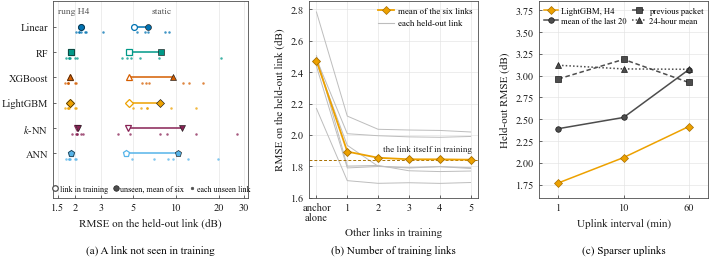

In [7]:
# Figure: generalization. (a) Each family fitted on five links and tested on the sixth, without history (notebook 15, k-NN from 14) and on rung H4
# (13 and 14); (b) LightGBM on rung H4 fitted on one to five other links (15); (c) sparser uplinks (15), with the values at every packet, one a
# minute, from the estimators of notebook 17. Drawn here because it needs the results of both notebooks.
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
import paper_figures as pf
pf.use()
static = pd.read_csv("CV_Results/unseen_link_static.csv")
history = pd.read_csv("CV_Results/unseen_link_by_family.csv")
links = pd.read_csv("CV_Results/links_curve_H4.csv")
sparse = pd.read_csv("CV_Results/sparse_uplinks.csv").set_index(["predictor", "uplink interval"])["hold-out RMSE"]
every_packet = pd.read_csv("CV_Results/adr_estimators.csv").query("calibration == 'SF x hours'").set_index("estimator")["rmse"]
fig = plt.figure(figsize=(pf.PAGE, 2.5))
gs = fig.add_gridspec(1, 3, width_ratios=[1.15, 1, 1], wspace=0.34, left=0.075, right=0.99, top=0.985, bottom=0.2)
a, b, c = (fig.add_subplot(gs[0, i]) for i in range(3))

# (a) the mean over the six links, open with the link in training and filled on the unseen link; each unseen link as a small dot
for i, fam in enumerate(pf.FAMILIES):
    for frame in (static, history):
        rows = frame[frame.family == fam]
        seen, unseen = rows["RMSE with the link in training"].mean(), rows["RMSE on the unseen link"].mean()
        assert 1.4 < min(seen, rows["RMSE on the unseen link"].min()) and rows["RMSE on the unseen link"].max() < 32      # nothing clipped
        marker = pf.MARKER[fam]
        a.plot(rows["RMSE on the unseen link"], np.full(len(rows), i) + 0.22, "o", ms=1.8, color=pf.COLOUR[fam], alpha=0.75, mew=0, zorder=2)
        a.plot([seen, unseen], [i, i], color=pf.COLOUR[fam], lw=1.1, zorder=2)
        a.plot(seen, i, marker=marker, ms=pf.MARKER_SIZE[marker], mfc="white", mec=pf.COLOUR[fam], mew=0.9, ls="none", zorder=3)
        a.plot(unseen, i, marker=marker, ms=pf.MARKER_SIZE[marker], mfc=pf.COLOUR[fam], mec=pf.INK, mew=0.45, ls="none", zorder=4)
a.set_xscale("log")
a.set_xlim(1.4, 32)
a.xaxis.set_major_locator(mticker.FixedLocator([1.5, 2, 3, 5, 10, 20, 30]))
a.xaxis.set_major_formatter(mticker.FixedFormatter(["1.5", "2", "3", "5", "10", "20", "30"]))
a.xaxis.set_minor_locator(mticker.NullLocator())
a.set_yticks(range(len(pf.FAMILIES)))
a.set_yticklabels([pf.NAME[f] for f in pf.FAMILIES])
a.set_ylim(6.75, -1.0)
a.grid(axis="y", visible=False)
a.text(1.95, -0.6, "rung H4", ha="center", va="center", fontsize=6.8, color=pf.INK2)
a.text(8.0, -0.6, "static", ha="center", va="center", fontsize=6.8, color=pf.INK2)
a.set_xlabel("RMSE on the held-out link (dB)")
a.legend(handles=[Line2D([], [], marker="o", ls="none", ms=4, mfc="white", mec=pf.INK2, mew=0.9, label="link in training"),
                  Line2D([], [], marker="o", ls="none", ms=4, mfc=pf.INK2, mec=pf.INK, mew=0.45, label="unseen, mean of six"),
                  Line2D([], [], marker="o", ls="none", ms=1.8, color=pf.INK2, label="each unseen link")],
         loc="lower center", ncol=3, fontsize=5.9, handletextpad=0.05, columnspacing=0.45, borderaxespad=0.15, handlelength=1.0)

# (b) the number of other links in training; 0 is the anchor alone, and the reference (dashed) has the link itself in training
assert links.RMSE.between(1.6, 2.85).all()                                       # nothing clipped
for link, rows in links[links["training links"] <= 5].groupby("held-out link"):
    rows = rows.sort_values("training links")
    b.plot(rows["training links"], rows.RMSE, color="#bdbdbd", lw=0.7, zorder=1)
mean = links[links["training links"] <= 5].groupby("training links").RMSE.mean()
b.plot(mean.index, mean.values, color=pf.AMBER, lw=1.3, marker="D", ms=3.8, mfc=pf.AMBER, mec=pf.AMBER_DARK, mew=0.6, zorder=3)
with_link = links[links["training links"] == 6].RMSE.mean()
b.axhline(with_link, color=pf.AMBER_DARK, lw=0.7, ls=(0, (3, 2)), zorder=2)
b.text(5.05, with_link + 0.045, "the link itself in training", ha="right", va="bottom", fontsize=6.6, color=pf.INK)
b.set_xticks(range(6))
b.set_xticklabels(["anchor\nalone", "1", "2", "3", "4", "5"], linespacing=0.95)
b.set_xlim(-0.25, 5.25)
b.set_ylim(1.6, 2.85)
b.set_xlabel("Other links in training")
b.set_ylabel("RMSE on the held-out link (dB)")
b.legend(handles=[Line2D([], [], color=pf.AMBER, lw=1.3, marker="D", ms=3.8, mfc=pf.AMBER, mec=pf.AMBER_DARK, label="mean of the six links"),
                  Line2D([], [], color="#bdbdbd", lw=0.8, label="each held-out link")], loc="upper right", fontsize=6.4, borderaxespad=0.2)

# (c) the uplink interval: every packet (1 min), every tenth and every sixtieth packet kept; ticks at the three tested intervals only
PREDICTORS = [("LightGBM on rung H4", "LightGBM on rung H4", "LightGBM, H4", pf.AMBER, pf.AMBER_DARK, "D", "-"),
              ("mean of the previous 20 kept packets", "mean of the last 20", "mean of the last 20", pf.INK2, pf.INK, "o", "-"),
              ("previous kept packet", "previous packet", "previous packet", pf.INK2, pf.INK, "s", (0, (3, 1.8))),
              ("mean of the previous 24 hours", "24 hour mean", "24-hour mean", pf.INK2, pf.INK, "^", (0, (1, 1.4)))]
for name, name_every_packet, label, colour, edge, marker, ls in PREDICTORS:
    rmse = [every_packet[name_every_packet], sparse[(name, "every 10 min")], sparse[(name, "every 60 min")]]
    assert 1.6 < min(rmse) and max(rmse) < 3.85                                   # nothing clipped
    c.plot([0, 1, 2], rmse, color=colour, lw=1.1, ls=ls, marker=marker, ms=4.0, mfc=colour, mec=edge, mew=0.5, label=label, zorder=3)
c.set_xticks([0, 1, 2])
c.set_xticklabels(["1", "10", "60"])
c.xaxis.set_minor_locator(mticker.NullLocator())
c.set_xlim(-0.3, 2.3)
c.set_ylim(1.6, 3.85)
c.set_xlabel("Uplink interval (min)")
c.set_ylabel("Held-out RMSE (dB)")
c.legend(loc="upper center", ncol=2, fontsize=6.2, borderaxespad=0.25, labelspacing=0.25, handlelength=1.7, columnspacing=0.6, handletextpad=0.3)
pf.subcaptions(fig, [a, b, c], ["(a) A link not seen in training", "(b) Number of training links", "(c) Sparser uplinks"])
fig.savefig("Figures/generalization.png")
plt.show()

**Notes.**

* The table of devices carries the geometry of the data paper; the data columns `distance`, `c_walls` and `w_walls` of the modelling files agree with it (they are read from the data, the room and the line of sight from the paper).
* The median interval between packets is the sampling rate the reviewers asked for: 60 s by design, longer at SF11 and SF12 because the duty-cycle scheduler of the LoRaWAN stack spaces the long packets, and longer still where packets were lost.
* The hyperparameters of the static tree models are read from the fitted models and asserted equal to the best rows of the saved searches, so the table cannot drift from what was run.
* The LaTeX tables in `Tables/` are the ones the manuscript includes; the CSV files in `CV_Results/` hold the same numbers.